# Paper 13: BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding
**Authors**: Jacob Devlin, Ming-Wei Chang, Kenton Lee, Kristina Toutanova (Google AI Language, 2018)

---

## 1. The Historical Breaking Point: The Unidirectional Bottleneck
Prior to BERT, pre-trained Transformer language models (such as OpenAI GPT-1) were constrained by **left-to-right unidirectional masking**:
- Token $i$ could only attend to previous tokens $1, \dots, i-1$.
- For reading comprehension, question answering, and sequence labeling, left-to-right conditioning is severely crippled because understanding word meaning requires context from **both** directions.
- Traditional multi-layer Transformers could not train bidirectionally because higher layers would trivially "see themselves" in the target prediction, causing identity shortcut collapse.

## 2. The First-Principles Breakthrough: Cloze Masking & NSP
Devlin et al. resolved the identity leak using the **Cloze procedure**:
1. **Masked Language Modeling (MLM)**: Corrupt 15% of tokens (80% `[MASK]`, 10% random, 10% unchanged) and train the bidirectional Transformer to reconstruct only the masked tokens.
2. **Next Sentence Prediction (NSP)**: Feed paired sentences `[CLS] A [SEP] B [SEP]` and classify whether $B$ follows $A$ from the pooled `[CLS]` token representation.
3. **Tripartite Embeddings**: Sum Token + Positional + Segment (Type) embeddings before LayerNorm.

In this notebook, you will develop and verify:
1. `BERTEmbedding` (Token + Position + Segment)
2. `BERTSelfAttention`, `BERTSelfOutput`, and `BERTAttention`
3. `BERTIntermediate` & `BERTOutput` (GELU FFN)
4. `BERTLayer` & `BERTEncoder`
5. `BERTPooler` ([CLS] projection)
6. Full `BERTModel` and `BERTForPreTraining`

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from model import (
    BERTEmbedding,
    BERTSelfAttention,
    BERTSelfOutput,
    BERTAttention,
    BERTIntermediate,
    BERTOutput,
    BERTLayer,
    BERTEncoder,
    BERTPooler,
    BERTModel,
    BERTLMPredictionHead,
    BERTForPreTraining,
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


---
## 1. Test BERTEmbedding: Token + Position + Segment Sum
Verify that changing `token_type_ids` (sentence A vs sentence B) properly alters the representation.

In [6]:
vocab_size, hidden_size = 100, 64
emb = BERTEmbedding(vocab_size=vocab_size, hidden_size=hidden_size, hidden_dropout_prob=0.0)
emb.eval()

input_ids = torch.randint(0, vocab_size, (2, 8))
token_type_ids = torch.zeros(2, 8, dtype=torch.long)
token_type_ids[:, 4:] = 1  # Second half is Sentence B

out = emb(input_ids, token_type_ids=token_type_ids)
print("Embedding output shape:", out.shape)  # Expected: (2, 8, 64)
assert out.shape == (2, 8, hidden_size)
print("BERTEmbedding PASSED!")

Embedding output shape: torch.Size([2, 8, 64])
BERTEmbedding PASSED!


---
## 2. Verify Deep Bidirectionality
Unlike causal GPT decoders, BERT self-attention allows future tokens ($t+k$) to directly alter earlier representations ($t$).

In [3]:
attn = BERTSelfAttention(hidden_size=64, num_attention_heads=4, attention_probs_dropout_prob=0.0)
attn.eval()

x1 = torch.randn(1, 6, 64)
x2 = x1.clone()
x2[:, 5, :] = torch.randn(64)  # Change future token at position 5

out1, probs1 = attn(x1)
out2, probs2 = attn(x2)

diff_step_0 = (out1[:, 0, :] - out2[:, 0, :]).abs().max().item()
print(f"Difference at position 0 when changing position 5: {diff_step_0:.4f}")
assert diff_step_0 > 1e-4, "BERT must be bidirectional!"
print("Bidirectionality contract PASSED!")

Difference at position 0 when changing position 5: 0.2759
Bidirectionality contract PASSED!


---
## 3. Test BERTPooler: [CLS] Representation
Extracts token 0 and applies a dense layer with $\tanh$ activation.

In [7]:
pooler = BERTPooler(hidden_size=64)
pooler.eval()

h = torch.randn(2, 10, 64)
pooled = pooler(h)
print("Pooled output shape:", pooled.shape)  # Expected: (2, 64)
assert pooled.shape == (2, 64)
assert (pooled >= -1.0).all() and (pooled <= 1.0).all()
print("BERTPooler PASSED!")

Pooled output shape: torch.Size([2, 64])
BERTPooler PASSED!


---
## 4. Single-Batch Overfit: Joint MLM + NSP Pre-training
Train `BERTForPreTraining` to simultaneously recover a masked token and predict sentence adjacency.

Epoch 15 | MLM: 0.7632 | NSP: 0.2068 | Total: 0.9700
Epoch 30 | MLM: 0.2679 | NSP: 0.0069 | Total: 0.2748
Epoch 45 | MLM: 0.1131 | NSP: 0.0024 | Total: 0.1156
Epoch 60 | MLM: 0.0646 | NSP: 0.0017 | Total: 0.0663


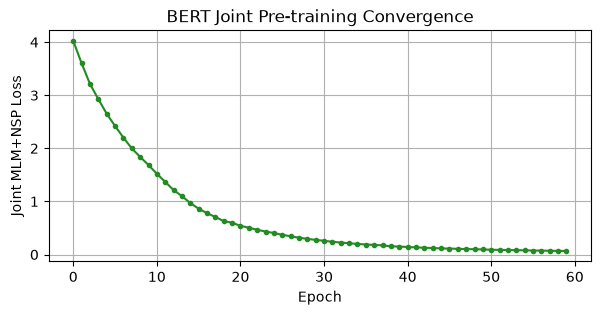

Joint MLM+NSP overfit check PASSED! Final loss: 0.0663


In [8]:
torch.manual_seed(42)
vocab_size, hidden_size = 30, 64
B, T = 2, 8

model = BERTForPreTraining(
    vocab_size=vocab_size,
    hidden_size=hidden_size,
    num_hidden_layers=2,
    num_attention_heads=4,
    intermediate_size=128,
    hidden_dropout_prob=0.0,
)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_mlm_fn = nn.CrossEntropyLoss()
loss_nsp_fn = nn.CrossEntropyLoss()

# Construct synthetic paired inputs: [CLS]=1, [SEP]=2, [MASK]=0
input_ids = torch.randint(3, vocab_size, (B, T))
input_ids[:, 0] = 1
input_ids[:, 4] = 2
input_ids[:, 7] = 2

token_type_ids = torch.zeros(B, T, dtype=torch.long)
token_type_ids[:, 5:] = 1

mlm_target = input_ids.clone()
input_ids[:, 2] = 0  # Mask position 2
nsp_target = torch.tensor([1, 0])  # Pair 0 is IsNext, Pair 1 is NotNext

losses = []
for epoch in range(60):
    optimizer.zero_grad()
    mlm_logits, nsp_logits = model(input_ids, token_type_ids=token_type_ids)
    l_mlm = loss_mlm_fn(mlm_logits.view(-1, vocab_size), mlm_target.view(-1))
    l_nsp = loss_nsp_fn(nsp_logits, nsp_target)
    loss = l_mlm + l_nsp
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:2d} | MLM: {l_mlm.item():.4f} | NSP: {l_nsp.item():.4f} | Total: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, marker='o', markersize=3, color='forestgreen')
plt.xlabel('Epoch')
plt.ylabel('Joint MLM+NSP Loss')
plt.title('BERT Joint Pre-training Convergence')
plt.grid(True)
plt.show()

assert losses[-1] < 0.1
print(f"Joint MLM+NSP overfit check PASSED! Final loss: {losses[-1]:.4f}")